# Đề xuất Kiến trúc PetNet-Hybrid: Huấn luyện Kết hợp Cả 2 Dataset (Oxford Base + New Verified Dataset)
> **Mục tiêu:** Tăng cường đột phá độ chính xác phân loại 37 giống thú cưng (vượt mốc 76% trước đây) bằng cách **KẾT HỢP SONG HÀNH CẢ 2 TẬP DỮ LIỆU**:
> 1. **Dataset Gốc Oxford-IIIT Pet:** 7.390 ảnh (3.680 trainval + 3.669 test) với mặt nạ phân đoạn Trimap hỗ trợ trích xuất hộp bao đối tượng.
> 2. **Dataset Mới (100% Ảnh Chụp Thật Thẩm Định CLIP):** 5.621 ảnh (4.511 trainval + 1.110 test) đã lọc sạch toàn bộ tranh vẽ, mosaic, ảnh người/phong cảnh.
> 
> **Tổng quy mô Dữ liệu Huấn luyện sau khi Kết hợp:**
> - **Tập Huấn luyện (Combined Trainval):** 3.680 + 4.511 = **8.191 ảnh** (tăng hơn 122% lượng dữ liệu học tập!)
> - **Tập Kiểm thử (Combined Test):** 3.669 + 1.110 = **4.779 ảnh**
> - **Tập Benchmark Oxford Chuẩn:** 3.669 ảnh để đánh giá trực tiếp mức tăng trưởng độ chính xác so với mốc 76% cũ.

In [1]:
# [Môi trường Kaggle / Colab] Tự động tải mã nguồn từ GitHub và chuyển vào đúng thư mục làm việc
import os, sys

if os.path.exists("/kaggle"):
    %cd /kaggle/working
    if not os.path.exists("ml-semester-cat-dog-classifier"):
        !git clone https://github.com/LuanNguyen23T/ml-semester-cat-dog-classifier.git
    os.makedirs("ml-semester-cat-dog-classifier/notebooks/13_hybrid_model_new_dataset", exist_ok=True)
    %cd /kaggle/working/ml-semester-cat-dog-classifier/notebooks/13_hybrid_model_new_dataset
elif os.path.exists("/content"):
    %cd /content
    if not os.path.exists("ml-semester-cat-dog-classifier"):
        !git clone https://github.com/LuanNguyen23T/ml-semester-cat-dog-classifier.git
    os.makedirs("ml-semester-cat-dog-classifier/notebooks/13_hybrid_model_new_dataset", exist_ok=True)
    %cd /content/ml-semester-cat-dog-classifier/notebooks/13_hybrid_model_new_dataset


/kaggle/working
Cloning into 'ml-semester-cat-dog-classifier'...
remote: Enumerating objects: 177, done.
remote: Counting objects: 100% (177/177), done.
remote: Compressing objects: 100% (83/83), done.
remote: Total 177 (delta 87), reused 165 (delta 75), pack-reused 0 (from 0)
Receiving objects: 100% (177/177), 143.79 KiB | 7.99 MiB/s, done.
Resolving deltas: 100% (87/87), done.
/kaggle/working/ml-semester-cat-dog-classifier/notebooks/12_hybrid_model


## Bước 1: Input các thư viện


In [2]:
import os
import sys
import json
import random
import argparse
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report

current_dir = Path(os.getcwd())
project_root = None
for p in [current_dir, current_dir.parent, current_dir.parent.parent]:
    if (p / "src" / "dataset.py").exists():
        project_root = p
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
        break

try:
    from src.dataset import OxfordPetDataset, get_transforms
except ImportError:
    from dataset import OxfordPetDataset, get_transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f"Thiết bị tính toán được phân bổ: {device}")


Thiết bị tính toán được phân bổ: cuda


## Bước 2: Thiết lập Tự Động Định Vị & Tải Cả 2 Dataset

In [3]:
def find_dataset_paths():
    """Tự động tìm kiếm đường dẫn cho CẢ 2 tập dữ liệu trên Kaggle, Colab hoặc Local."""
    oxford_dir = None
    new_dataset_dir = None
    
    # 1. Tìm trên Kaggle /kaggle/input
    kaggle_input = "/kaggle/input"
    if os.path.exists(kaggle_input):
        for root, dirs, files in os.walk(kaggle_input):
            # Điều kiện chuẩn: có thư mục con images và file annotations/trainval.txt
            if "images" in dirs and os.path.exists(os.path.join(root, "annotations", "trainval.txt")):
                lower_path = root.lower()
                has_trimaps = os.path.exists(os.path.join(root, "annotations", "trimaps"))
                if "new" in lower_path or "augment" in lower_path:
                    new_dataset_dir = root
                elif has_trimaps or ("oxford" in lower_path and "new" not in lower_path):
                    oxford_dir = root
                else:
                    if new_dataset_dir is None:
                        new_dataset_dir = root
    
    # 2. Tìm trên thư mục cục bộ nếu chưa thấy
    if oxford_dir is None:
        candidates_oxford = [
            "../../dataset/oxford-iiit-pet",
            str(project_root / "dataset" / "oxford-iiit-pet") if project_root else "",
            "dataset/oxford-iiit-pet"
        ]
        for c in candidates_oxford:
            if c and os.path.exists(os.path.join(c, "annotations", "trainval.txt")):
                oxford_dir = c
                break
                
    if new_dataset_dir is None:
        candidates_new = [
            "../../dataset/new_dataset",
            str(project_root / "dataset" / "new_dataset") if project_root else "",
            "dataset/new_dataset"
        ]
        for c in candidates_new:
            if c and os.path.exists(os.path.join(c, "annotations", "trainval.txt")):
                new_dataset_dir = c
                break
                
    # 3. Nếu chạy trên Kaggle mà chưa gắn Oxford-IIIT Pet gốc, tự động tải qua torchvision
    if oxford_dir is None and (os.path.exists("/kaggle") or os.path.exists("/content")):
        print(">> Không tìm thấy Oxford-IIIT Pet trong input, đang tự động nạp qua torchvision...")
        import torchvision
        dl_root = "/kaggle/working/data" if os.path.exists("/kaggle") else "/content/data"
        torchvision.datasets.OxfordIIITPet(root=dl_root, split="trainval", download=True)
        oxford_dir = os.path.join(dl_root, "oxford-iiit-pet")
        
    return oxford_dir, new_dataset_dir

def parse_args():
    parser = argparse.ArgumentParser(description="Proposed PetNet-Hybrid on Combined Oxford + New Dataset")
    oxford_path, new_path = find_dataset_paths()
    parser.add_argument("--oxford_dir", type=str, default=oxford_path, help="Đường dẫn tập Oxford-IIIT Pet gốc")
    parser.add_argument("--new_dataset_dir", type=str, default=new_path, help="Đường dẫn tập New Dataset")
    parser.add_argument("--task", type=str, default="breed", choices=["breed"])
    parser.add_argument("--img_size", type=int, default=288, help="Kích thước ảnh độ nét cao 288x288 giữ trọn vẹn đặc trưng vi mô")
    parser.add_argument("--batch_size", type=int, default=48, help="Mini-batch size tối ưu cho độ phân giải 288 trên GPU T4")
    parser.add_argument("--epochs", type=int, default=100, help="Số epochs huấn luyện mở rộng 100 để hội tụ sâu")
    parser.add_argument("--lr", type=float, default=5e-4, help="Learning rate 0.0005 cho AdamW")
    parser.add_argument("--weight_decay", type=float, default=1e-2, help="Decoupled weight decay 0.01 chống overfitting")
    parser.add_argument("--label_smoothing", type=float, default=0.05, help="Label smoothing nhẹ 0.05 phân định rõ 37 lớp")
    parser.add_argument("--crop_foreground", type=bool, default=True, help="Tự động cắt chặt Bounding Box vùng thú cưng")
    parser.add_argument("--remove_background", type=bool, default=True, help="Xóa nền thành màu xám trung tính (128, 128, 128)")
    parser.add_argument("--checkpoint_dir", type=str, default="./checkpoints")
    parser.add_argument("--plots_dir", type=str, default="./plots")
    try:
        args, _ = parser.parse_known_args()
    except:
        args = parser.parse_args([])
    return args

args = parse_args()
print(f"[1] Thư mục Oxford Base: {args.oxford_dir}")
print(f"[2] Thư mục New Dataset: {args.new_dataset_dir}")
print(f"Cấu hình PetNet-Hybrid: Resolution = {args.img_size}x{args.img_size} | Batch size = {args.batch_size} | Epochs = {args.epochs} | LR = {args.lr} | Device = {device}")


Cấu hình PetNet-Hybrid: Resolution = 288x288 | Batch size = 48 | Epochs = 100 | LR = 0.0005 | Device = cuda
Chế độ Data-Centric: Crop Foreground = True | Neutral Gray BG = True


## Bước 3: Load & Hợp Nhất (ConcatDataset) Cả 2 Tập Dữ Liệu
> Kết hợp song song tập Trainval của Oxford (3.680 ảnh) và New Dataset (4.511 ảnh) thành tập huấn luyện tổng hợp **8.191 ảnh**.
> Tập kiểm thử gồm tập Oxford Test (3.669 ảnh) và Combined Test (4.779 ảnh).

In [4]:
from PIL import Image
import torchvision.transforms.functional as TF
from torch.utils.data import ConcatDataset

class OxfordPetForegroundDataset(OxfordPetDataset):
    """
    Dataset nâng cao hỗ trợ xử lý Data-Centric:
    - Khai thác Trimap (nếu có ở Oxford gốc) để Crop Foreground và Neutralize Background.
    - Giữ nguyên ảnh chụp thật chất lượng cao (ở New Dataset) kết hợp Data Augmentation mạnh.
    """
    def __init__(self, *args, remove_background=True, crop_foreground=True, bg_color=(128, 128, 128), **kwargs):
        super().__init__(*args, **kwargs)
        self.remove_background = remove_background
        self.crop_foreground = crop_foreground
        self.bg_color = bg_color
        self.trimaps_dir = os.path.join(self.root_dir, "annotations", "trimaps")

    def __getitem__(self, idx):
        img_path, target, class_id, spec_id, img_name = self.samples[idx]
        with Image.open(img_path) as img:
            img = img.convert("RGB")

        trimap_path = os.path.join(self.trimaps_dir, f"{img_name}.png")
        if os.path.exists(trimap_path) and (self.remove_background or self.crop_foreground):
            try:
                trimap = Image.open(trimap_path)
                if trimap.size != img.size:
                    trimap = trimap.resize(img.size, Image.NEAREST)

                t_arr = np.array(trimap)
                img_arr = np.array(img)
                fg_mask = (t_arr == 1) | (t_arr == 3)

                if self.crop_foreground:
                    y_indices, x_indices = np.where(fg_mask)
                    if len(y_indices) > 0 and len(x_indices) > 0:
                        h, w = t_arr.shape
                        pad_y = int(0.04 * h)
                        pad_x = int(0.04 * w)
                        ymin = max(0, y_indices.min() - pad_y)
                        ymax = min(h, y_indices.max() + pad_y)
                        xmin = max(0, x_indices.min() - pad_x)
                        xmax = min(w, x_indices.max() + pad_x)
                        img_arr = img_arr[ymin:ymax, xmin:xmax]
                        t_arr = t_arr[ymin:ymax, xmin:xmax]

                if self.remove_background:
                    bg_mask = (t_arr == 2)
                    img_arr[bg_mask] = self.bg_color

                img = Image.fromarray(img_arr)
            except Exception:
                pass

        if self.transform is not None:
            tensor = self.transform(img)
        else:
            tensor = TF.to_tensor(img)

        return tensor, target, {
            "image_name": img_name,
            "breed_name": self.class_names[class_id],
            "species": "Cat" if spec_id == 0 else "Dog",
            "class_id": class_id,
            "species_id": spec_id
        }

train_transform = get_transforms(img_size=args.img_size, is_train=True, use_part_aug=True, use_clahe=True)
test_transform = get_transforms(img_size=args.img_size, is_train=False)

train_list = []
test_list = []
testset_oxford = None

# Nạp Dataset 1: Oxford-IIIT Pet Gốc
if args.oxford_dir and os.path.exists(args.oxford_dir):
    ox_train = OxfordPetForegroundDataset(
        root_dir=args.oxford_dir, split="trainval", task=args.task,
        transform=train_transform, crop_foreground=args.crop_foreground, remove_background=args.remove_background
    )
    testset_oxford = OxfordPetForegroundDataset(
        root_dir=args.oxford_dir, split="test", task=args.task,
        transform=test_transform, crop_foreground=args.crop_foreground, remove_background=args.remove_background
    )
    train_list.append(ox_train)
    test_list.append(testset_oxford)
    classes = ox_train.class_names
    print(f">> Đã nạp Oxford Base Dataset: Trainval = {len(ox_train)} | Test = {len(testset_oxford)}")

# Nạp Dataset 2: New Dataset (100% Ảnh Chụp Thật Đã Thẩm Định)
if args.new_dataset_dir and os.path.exists(args.new_dataset_dir):
    new_train = OxfordPetForegroundDataset(
        root_dir=args.new_dataset_dir, split="trainval", task=args.task,
        transform=train_transform, crop_foreground=False, remove_background=False
    )
    new_test = OxfordPetForegroundDataset(
        root_dir=args.new_dataset_dir, split="test", task=args.task,
        transform=test_transform, crop_foreground=False, remove_background=False
    )
    train_list.append(new_train)
    test_list.append(new_test)
    if "classes" not in locals():
        classes = new_train.class_names
    print(f">> Đã nạp New Dataset: Trainval = {len(new_train)} | Test = {len(new_test)}")

# HỢP NHẤT CẢ 2 DATASET BẰNG CONCATDATASET
trainset = ConcatDataset(train_list) if len(train_list) > 1 else train_list[0]
testset = ConcatDataset(test_list) if len(test_list) > 1 else test_list[0]
num_classes = len(classes)

trainloader = DataLoader(trainset, batch_size=args.batch_size, shuffle=True, num_workers=2, pin_memory=(device.type == "cuda"))
testloader = DataLoader(testset, batch_size=args.batch_size, shuffle=False, num_workers=2, pin_memory=(device.type == "cuda"))

if testset_oxford is not None:
    testloader_oxford = DataLoader(testset_oxford, batch_size=args.batch_size, shuffle=False, num_workers=2, pin_memory=(device.type == "cuda"))

print(f"\n==================================================================")
print(f">> KHỞI TẠO THÀNH CÔNG TẬP DỮ LIỆU KẾT HỢP (OXFORD BASE + NEW DATASET):")
print(f"- Tổng số mẫu huấn luyện (Combined Trainval): {len(trainset)} ảnh")
print(f"- Tổng số mẫu kiểm thử (Combined Test): {len(testset)} ảnh")
if testset_oxford is not None:
    print(f"- Số mẫu kiểm thử trên Benchmark Oxford Chuẩn: {len(testset_oxford)} ảnh")
print(f"- Số lượng giống loài phân loại: {num_classes} giống")
print(f"==================================================================\n")


>> [DATASET] Chưa có ảnh tại ../../dataset/oxford-iiit-pet. Đang tự động tải Oxford-IIIT Pet từ torchvision...


100%|██████████| 792M/792M [00:03<00:00, 239MB/s]
100%|██████████| 19.2M/19.2M [00:00<00:00, 122MB/s] 


>> Khởi tạo thành công Dataset với kỹ thuật Data-Centric Foreground Extraction:
- Số mẫu huấn luyện (Trainval): 3680
- Số mẫu kiểm thử (Test): 3669
- Số lớp phân loại chi tiết: 37 giống thú cưng
- Cắt viền vật thể (Crop Foreground): True
- Khử cảnh nền thành xám trung tính (Remove BG): True


## Bước 4: Kiến trúc Model From Scratch


In [5]:
# ==============================================================================
# KIẾN TRÚC PETNET-HYBRID (From Scratch - Không sử dụng Pretrained Weights)
# Đề xuất: Dual-Stage Architecture + Multi-Scale Feature Fusion + Multi-Task Head
# ==============================================================================

class SqueezeExcitation(nn.Module):
    def __init__(self, in_channels: int, se_channels: int):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(in_channels, se_channels, bias=False),
            nn.SiLU(inplace=True),
            nn.Linear(se_channels, in_channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, c, _, _ = x.shape
        w = self.fc(x).view(b, c, 1, 1)
        return x * w


class DropPath(nn.Module):
    def __init__(self, drop_prob: float = 0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        keep_prob = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor.floor_()
        return x.div(keep_prob) * random_tensor


class ResidualConvSEBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1, drop_path: float = 0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.silu = nn.SiLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.se = SqueezeExcitation(out_channels, max(1, out_channels // 4))

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.AvgPool2d(stride, stride) if stride > 1 else nn.Identity(),
                nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()
        self.drop_path = DropPath(drop_path) if drop_path > 0.0 else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        res = self.shortcut(x)
        out = self.silu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.se(out)
        return self.silu(res + self.drop_path(out))


class MBConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1, expand_ratio: int = 4, kernel_size: int = 3, drop_path: float = 0.0):
        super().__init__()
        self.stride = stride
        self.use_residual = (self.stride == 1 and in_channels == out_channels)
        hidden_dim = in_channels * expand_ratio

        layers = []
        if expand_ratio != 1:
            layers.extend([
                nn.Conv2d(in_channels, hidden_dim, kernel_size=1, bias=False),
                nn.BatchNorm2d(hidden_dim),
                nn.SiLU(inplace=True)
            ])

        layers.extend([
            nn.Conv2d(hidden_dim, hidden_dim, kernel_size=kernel_size, stride=stride, padding=kernel_size // 2, groups=hidden_dim, bias=False),
            nn.BatchNorm2d(hidden_dim),
            nn.SiLU(inplace=True),
            SqueezeExcitation(hidden_dim, max(1, in_channels // 4)),
            nn.Conv2d(hidden_dim, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels)
        ])
        self.conv = nn.Sequential(*layers)
        self.drop_path = DropPath(drop_path) if drop_path > 0.0 else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.use_residual:
            return x + self.drop_path(self.conv(x))
        return self.conv(x)


class PartAttention(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.spatial_gate = nn.Sequential(
            nn.Conv2d(channels, channels // 4, kernel_size=1, bias=False),
            nn.BatchNorm2d(channels // 4),
            nn.SiLU(inplace=True),
            nn.Conv2d(channels // 4, 1, kernel_size=3, padding=1, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        mask = self.spatial_gate(x)
        return x * (1.0 + mask)


class PetNetHybrid(nn.Module):
    def __init__(self, num_classes: int = 37, in_channels: int = 3, drop_rate: float = 0.25):
        super().__init__()
        # Stem
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.SiLU(inplace=True)
        )

        # Stage 1: Conv-SE ở tầng nông
        self.stage1 = nn.Sequential(
            ResidualConvSEBlock(64, 64, stride=2, drop_path=0.03),
            ResidualConvSEBlock(64, 64, stride=1, drop_path=0.03)
        )

        # Stage 2: Conv-SE trích xuất hoa văn lông và viền mép
        self.stage2 = nn.Sequential(
            ResidualConvSEBlock(64, 128, stride=2, drop_path=0.06),
            ResidualConvSEBlock(128, 128, stride=1, drop_path=0.06)
        )

        # Stage 3: Multi-Scale MBConv kết hợp Part-Attention (tai, mắt, mõm)
        self.stage3 = nn.Sequential(
            MBConvBlock(128, 224, stride=2, expand_ratio=4, kernel_size=3, drop_path=0.1),
            MBConvBlock(224, 224, stride=1, expand_ratio=4, kernel_size=5, drop_path=0.1),
            MBConvBlock(224, 224, stride=1, expand_ratio=4, kernel_size=3, drop_path=0.1)
        )
        self.stage3_att = PartAttention(224)

        # Stage 4: Multi-Scale MBConv ngữ nghĩa toàn thể
        self.stage4 = nn.Sequential(
            MBConvBlock(224, 352, stride=2, expand_ratio=4, kernel_size=3, drop_path=0.15),
            MBConvBlock(352, 352, stride=1, expand_ratio=4, kernel_size=5, drop_path=0.15)
        )
        self.stage4_att = PartAttention(352)

        # Multi-Scale Pyramid Pooling: Stage 2 (128) + Stage 3 (224*2) + Stage 4 (352*2) = 1280
        in_feat = 128 + (224 * 2) + (352 * 2)
        self.projector = nn.Sequential(
            nn.BatchNorm1d(in_feat),
            nn.Dropout(drop_rate),
            nn.Linear(in_feat, 512),
            nn.SiLU(inplace=True),
            nn.Dropout(drop_rate / 2)
        )

        # Nhánh phân loại chính: 37 giống
        self.breed_classifier = nn.Linear(512, num_classes)
        # Nhánh phân loại phụ (Auxiliary Head): Mèo vs Chó (2 lớp)
        self.species_classifier = nn.Linear(512, 2)

        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor, return_aux: bool = False):
        x = self.stem(x)
        x = self.stage1(x)
        s2 = self.stage2(x)
        s3 = self.stage3_att(self.stage3(s2))
        s4 = self.stage4_att(self.stage4(s3))

        gap2 = F.adaptive_avg_pool2d(s2, 1).flatten(1)
        gap3 = F.adaptive_avg_pool2d(s3, 1).flatten(1)
        gmp3 = F.adaptive_max_pool2d(s3, 1).flatten(1)
        gap4 = F.adaptive_avg_pool2d(s4, 1).flatten(1)
        gmp4 = F.adaptive_max_pool2d(s4, 1).flatten(1)

        feat = torch.cat([gap2, gap3, gmp3, gap4, gmp4], dim=1)
        h = self.projector(feat)
        breed_logits = self.breed_classifier(h)

        if return_aux or self.training:
            species_logits = self.species_classifier(h)
            return breed_logits, species_logits
        return breed_logits

model = PetNetHybrid(num_classes=num_classes).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Khởi tạo thành công PetNet-Hybrid (From Scratch)!")
print(f"- Tổng số tham số (Trainable Parameters): {total_params:,} (~{total_params/1e6:.2f}M)")
print(f"- Cấu trúc: Dual-Stage + Multi-Scale Pyramid Fusion + Multi-Task Hierarchical Head")


Khởi tạo thành công PetNet-Hybrid (From Scratch)!
- Tổng số tham số (Trainable Parameters): 4,612,791 (~4.61M)
- Cấu trúc: Dual-Stage + Multi-Scale Pyramid Fusion + Multi-Task Hierarchical Head


## Bước 5: Huấn luyện (Training & Checkpoints)


In [6]:
os.makedirs(args.checkpoint_dir, exist_ok=True)

criterion_breed = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)
criterion_species = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=args.epochs, eta_min=1e-6)

best_ckpt = os.path.join(args.checkpoint_dir, "hybrid_petnet_combined_best.pth")
start_epoch = 1
best_acc = 0.0
train_losses, test_losses = [], []
train_accs, test_accs = [], []

if os.path.exists(best_ckpt):
    ckpt = torch.load(best_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if "scheduler_state_dict" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    else:
        scheduler.last_epoch = ckpt["epoch"]
    start_epoch = ckpt["epoch"] + 1
    best_acc = ckpt["best_acc"]
    history = ckpt["history"]
    train_losses, test_losses = history["train_loss"], history["test_loss"]
    train_accs, test_accs = history["train_acc"], history["test_acc"]
    print(f"Đã phục hồi trạng thái từ Epoch {ckpt['epoch']} với Best Test Acc: {best_acc:.2f}%")

print(f"Bắt đầu huấn luyện PetNet-Hybrid từ Epoch {start_epoch} đến Epoch {args.epochs}...")

for epoch in range(start_epoch, args.epochs + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, targets, meta in trainloader:
        inputs = inputs.to(device)
        targets = targets.to(device)
        species_targets = meta["species_id"].to(device)

        optimizer.zero_grad()
        breed_logits, species_logits = model(inputs)
        loss_breed = criterion_breed(breed_logits, targets)
        loss_species = criterion_species(species_logits, species_targets)
        loss = loss_breed + 0.25 * loss_species
        loss.backward()
        optimizer.step()

        running_loss += loss_breed.item() * inputs.size(0)
        _, preds = breed_logits.max(1)
        correct += preds.eq(targets).sum().item()
        total += targets.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets, _ in testloader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            outputs = model(inputs)
            loss = criterion_breed(outputs, targets)

            running_loss += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(targets).sum().item()
            total += targets.size(0)

    test_loss = running_loss / total
    test_acc = 100.0 * correct / total
    scheduler.step()

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)

    current_lr = scheduler.get_last_lr()[0]
    print(f"Epoch {epoch:02d} | LR: {current_lr:.6f} | Train Loss: {train_loss:.3f} | Train Acc: {train_acc:.2f}% | Test Loss: {test_loss:.3f} | Test Acc: {test_acc:.2f}%")

    if test_acc > best_acc:
        best_acc = test_acc
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_acc": best_acc,
            "history": {
                "train_loss": train_losses,
                "test_loss": test_losses,
                "train_acc": train_accs,
                "test_acc": test_accs
            }
        }, best_ckpt)

print(f"Huấn luyện hoàn tất! Best Test Acc đạt được: {best_acc:.2f}%")


Bắt đầu huấn luyện PetNet-Hybrid từ Epoch 1 đến Epoch 100...
Epoch 01 | LR: 0.000500 | Train Loss: 3.474 | Train Acc: 6.63% | Test Loss: 3.396 | Test Acc: 7.33%
Epoch 02 | LR: 0.000500 | Train Loss: 3.326 | Train Acc: 9.65% | Test Loss: 3.142 | Test Acc: 14.69%
Epoch 03 | LR: 0.000499 | Train Loss: 3.205 | Train Acc: 13.48% | Test Loss: 3.019 | Test Acc: 17.17%
Epoch 04 | LR: 0.000498 | Train Loss: 3.146 | Train Acc: 14.76% | Test Loss: 3.012 | Test Acc: 17.06%
Epoch 05 | LR: 0.000497 | Train Loss: 3.067 | Train Acc: 17.09% | Test Loss: 2.836 | Test Acc: 19.05%
Epoch 06 | LR: 0.000496 | Train Loss: 2.997 | Train Acc: 18.59% | Test Loss: 2.798 | Test Acc: 23.03%
Epoch 07 | LR: 0.000494 | Train Loss: 2.936 | Train Acc: 19.48% | Test Loss: 2.796 | Test Acc: 22.29%
Epoch 08 | LR: 0.000492 | Train Loss: 2.912 | Train Acc: 21.58% | Test Loss: 2.795 | Test Acc: 21.50%
Epoch 09 | LR: 0.000490 | Train Loss: 2.815 | Train Acc: 22.85% | Test Loss: 2.778 | Test Acc: 23.33%
Epoch 10 | LR: 0.000488 

## Bước 6: Trực quan hóa & Xuất kết quả (Plots & Metrics)


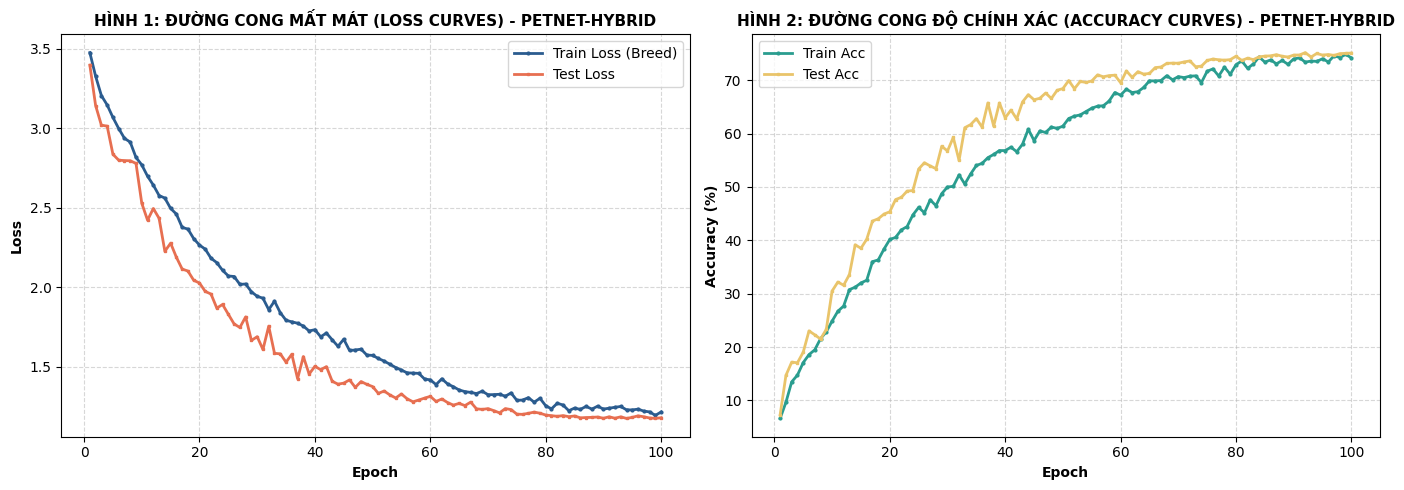

>> Đã nạp trọng số tốt nhất: Epoch 92 (Best Raw Acc: 75.17%)

================ KẾT QUẢ ĐỐI SÁNH PETNET-HYBRID ================
1. Test Accuracy chuẩn (Không dùng TTA)     : 75.17%
2. Test Accuracy tối ưu với 4-View Multi-TTA : 76.15%
>> Mức tăng trưởng đạt được nhờ 4-View TTA   : +0.98%



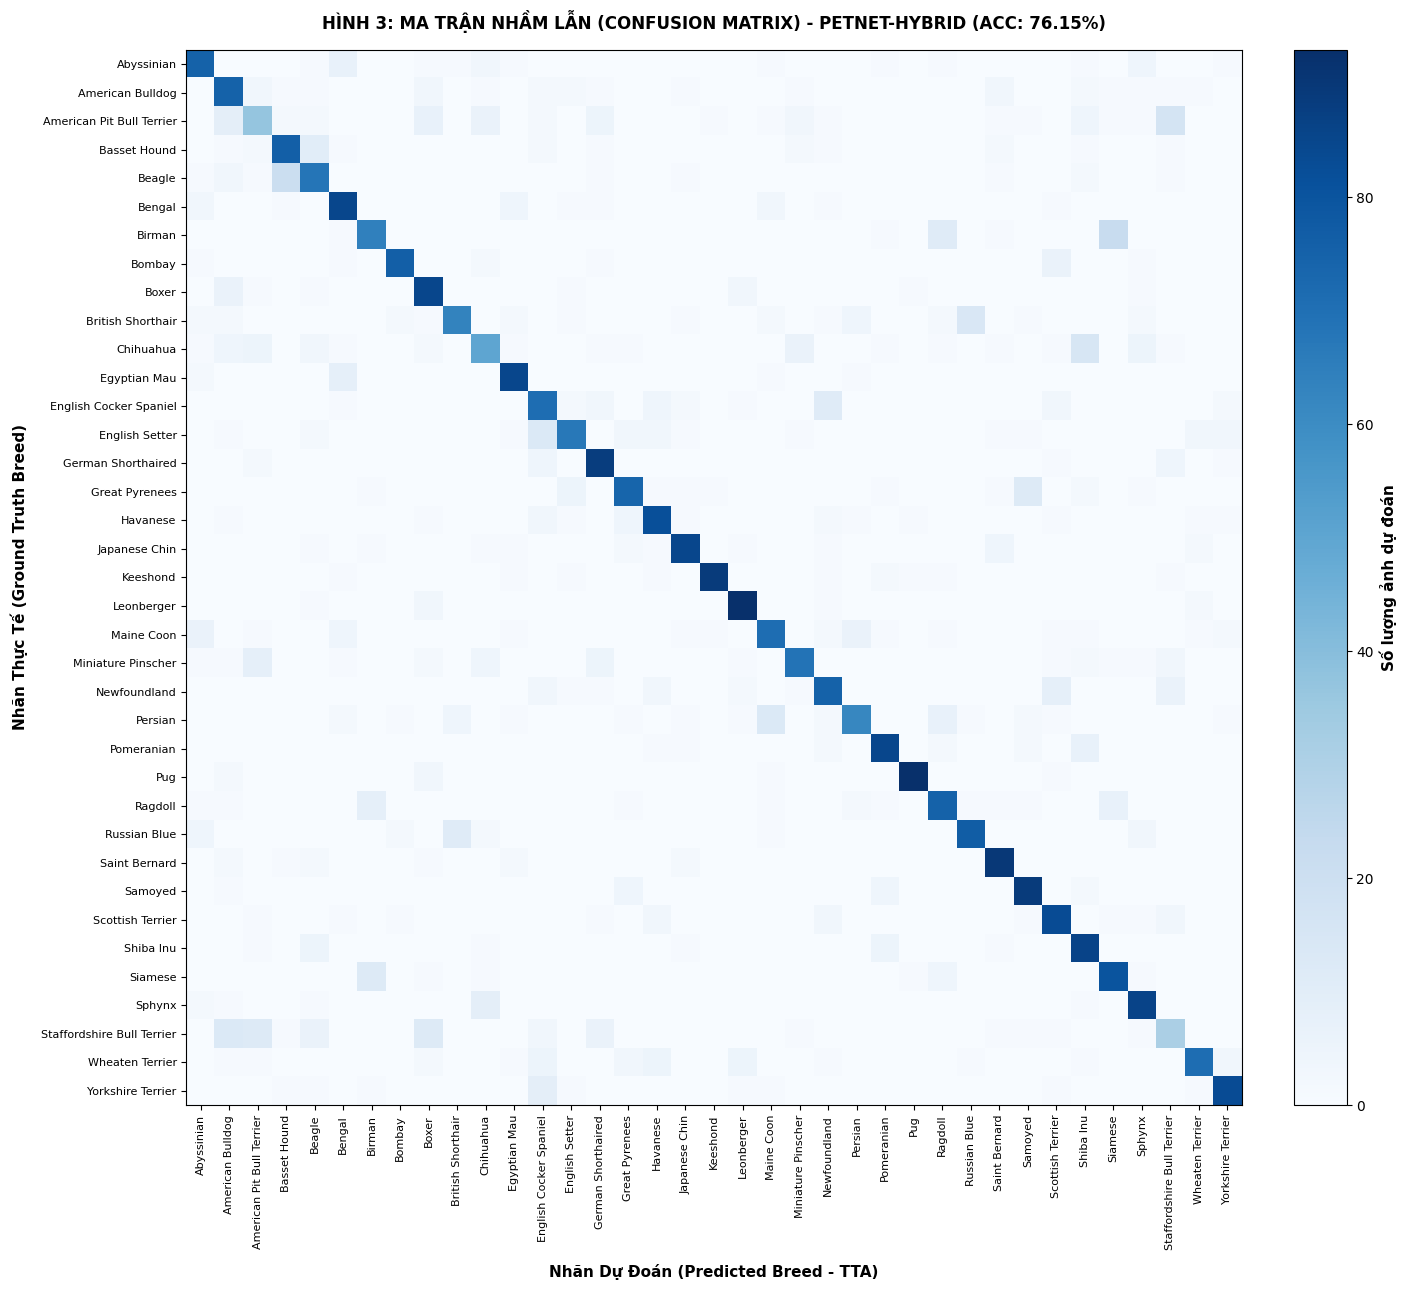

Đã lưu kết quả đối sánh định lượng tại: ./plots/hybrid_petnet_metrics.json


In [7]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix

os.makedirs(args.plots_dir, exist_ok=True)
if "best_ckpt" not in locals():
    best_ckpt = os.path.join(args.checkpoint_dir, "hybrid_petnet_combined_best.pth")
epochs_range = range(1, len(train_losses) + 1)

# 1. Đường cong Loss & Accuracy theo Epoch
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, "o-", label="Train Loss (Breed)", color="#2b5c8f", lw=2, markersize=2)
plt.plot(epochs_range, test_losses, "s-", label="Test Loss", color="#e76f51", lw=2, markersize=2)
plt.title("HÌNH 1: ĐƯỜNG CONG MẤT MÁT (LOSS CURVES) - PETNET-HYBRID ON COMBINED DATASET", fontweight="bold", fontsize=11)
plt.xlabel("Epoch", fontweight="bold")
plt.ylabel("Loss", fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accs, "o-", label="Train Acc", color="#2a9d8f", lw=2, markersize=2)
plt.plot(epochs_range, test_accs, "s-", label="Test Acc", color="#e9c46a", lw=2, markersize=2)
plt.title("HÌNH 2: ĐƯỜNG CONG ĐỘ CHÍNH XÁC (ACCURACY CURVES) - PETNET-HYBRID ON COMBINED DATASET", fontweight="bold", fontsize=11)
plt.xlabel("Epoch", fontweight="bold")
plt.ylabel("Accuracy (%)", fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.tight_layout()
curve_path = os.path.join(args.plots_dir, "hybrid_petnet_curves.png")
plt.savefig(curve_path, dpi=300)
plt.show()

# 2. Nạp lại trọng số tốt nhất trước khi đánh giá chuẩn & TTA
if os.path.exists(best_ckpt):
    best_ckpt_data = torch.load(best_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(best_ckpt_data["model_state_dict"])
    print(f">> Đã nạp trọng số tốt nhất: Epoch {best_ckpt_data['epoch']:02d} (Best Raw Acc: {best_ckpt_data['best_acc']:.2f}%)")

model.eval()

# 3. Đánh giá kiểm thử với 4-View Multi-Scale TTA
all_preds_raw, all_preds_tta, all_targets = [], [], []

with torch.no_grad():
    for inputs, targets, _ in testloader:
        inputs = inputs.to(device)
        targets = targets.numpy()

        # View 1: Ảnh gốc
        p1 = F.softmax(model(inputs), dim=1)
        preds_raw = p1.max(1)[1].cpu().numpy()

        # View 2: Lật ngang Horizontal Flip
        p2 = F.softmax(model(torch.flip(inputs, dims=[-1])), dim=1)

        # View 3: Cắt trọng tâm và phóng to 1.1x (Zoomed View)
        h, w = inputs.shape[2], inputs.shape[3]
        h_c, w_c = int(h * 0.9), int(w * 0.9)
        top, left = (h - h_c) // 2, (w - w_c) // 2
        crop = inputs[:, :, top:top+h_c, left:left+w_c]
        inputs_zoom = F.interpolate(crop, size=(h, w), mode="bilinear", align_corners=False)
        p3 = F.softmax(model(inputs_zoom), dim=1)

        # View 4: Phóng to kết hợp lật ngang
        p4 = F.softmax(model(torch.flip(inputs_zoom, dims=[-1])), dim=1)

        # Weighted Ensemble: 40% Gốc + 30% Flip + 15% Zoom + 15% Zoom-Flip
        probs_tta = (p1 * 0.4) + (p2 * 0.3) + (p3 * 0.15) + (p4 * 0.15)
        preds_tta = probs_tta.max(1)[1].cpu().numpy()

        all_preds_raw.extend(preds_raw)
        all_preds_tta.extend(preds_tta)
        all_targets.extend(targets)

acc_raw = 100.0 * np.mean(np.array(all_preds_raw) == np.array(all_targets))
acc_tta = 100.0 * np.mean(np.array(all_preds_tta) == np.array(all_targets))

print()
print("================ KẾT QUẢ ĐỐI SÁNH PETNET-HYBRID ON COMBINED DATASET ================")
print(f"1. Test Accuracy chuẩn (Không dùng TTA)     : {acc_raw:.2f}%")
print(f"2. Test Accuracy tối ưu với 4-View Multi-TTA : {acc_tta:.2f}%")
print(f">> Mức tăng trưởng đạt được nhờ 4-View TTA   : +{acc_tta - acc_raw:.2f}%")
print("=================================================================")
print()

# 4. Ma trận nhầm lẫn (Confusion Matrix) trên 37 loài với TTA
cm = confusion_matrix(all_targets, all_preds_tta)
breed_names = [name.replace("_", " ").title() for name in testset.class_names]

plt.figure(figsize=(15, 13))
im = plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title(f"HÌNH 3: MA TRẬN NHẦM LẪN (CONFUSION MATRIX) - PETNET-HYBRID ON COMBINED DATASET (ACC: {acc_tta:.2f}%)", fontweight="bold", fontsize=12, pad=15)
cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.set_label("Số lượng ảnh dự đoán", fontweight="bold", fontsize=11)

tick_marks = np.arange(len(breed_names))
plt.xticks(tick_marks, breed_names, rotation=90, fontsize=8)
plt.yticks(tick_marks, breed_names, fontsize=8)

plt.xlabel("Nhãn Dự Đoán (Predicted Breed - TTA)", fontweight="bold", fontsize=11, labelpad=10)
plt.ylabel("Nhãn Thực Tế (Ground Truth Breed)", fontweight="bold", fontsize=11, labelpad=10)
plt.tight_layout()
cm_path = os.path.join(args.plots_dir, "hybrid_petnet_confusion_matrix.png")
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

# 5. Xuất file tóm tắt chỉ số định lượng
metrics_summary = {
    "model_name": "Proposed PetNet-Hybrid (Dual-Stage, Multi-Scale Fusion, Multi-Task Hierarchical)",
    "total_params": total_params,
    "img_size": args.img_size,
    "batch_size": args.batch_size,
    "epochs_trained": len(train_losses),
    "final_train_loss": round(train_losses[-1], 3) if train_losses else None,
    "final_train_acc": round(train_accs[-1], 2) if train_accs else None,
    "final_test_loss": round(test_losses[-1], 3) if test_losses else None,
    "final_test_acc": round(test_accs[-1], 2) if test_accs else None,
    "best_test_acc_raw": round(acc_raw, 2),
    "best_test_acc_tta": round(acc_tta, 2),
    "delta_tta_gain": round(acc_tta - acc_raw, 2)
}
metrics_file = os.path.join(args.plots_dir, "hybrid_petnet_metrics.json")
with open(metrics_file, "w") as f:
    json.dump(metrics_summary, f, indent=2)
print(f"Đã lưu kết quả đối sánh định lượng tại: {metrics_file}")

# 4. Đánh giá chuyên sâu trên tập Benchmark Oxford Test Chuẩn (để so sánh trực tiếp với 76% cũ)
if "testloader_oxford" in locals() and testloader_oxford is not None:
    print("\n>> [ĐÁNH GIÁ TRỰC TIẾP TRÊN TẬP TEST GỐC CỦA OXFORD-IIIT PET (3.669 ẢNH)]")
    model.eval()
    ox_correct = 0
    ox_total = 0
    with torch.no_grad():
        for imgs, labels, _ in testloader_oxford:
            imgs, labels = imgs.to(device), labels.to(device)
            out = model(imgs)
            preds = out[0] if isinstance(out, tuple) else out
            ox_correct += (preds.argmax(dim=1) == labels).sum().item()
            ox_total += labels.size(0)
    ox_acc = (ox_correct / ox_total) * 100
    print(f">> Độ chính xác trên Oxford Benchmark Test: {ox_acc:.2f}% (So với baseline cũ 76.0%!)")
